# EDA Raw Data

## 1. Set up

In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plt.rcParams.update({
    'figure.facecolor': '#0f1117',
    'axes.facecolor':   '#1a1d27',
    'axes.edgecolor':   '#3a3d52',
    'axes.labelcolor':  '#c9d1d9',
    'text.color':       '#c9d1d9',
    'xtick.color':      '#8b949e',
    'ytick.color':      '#8b949e',
    'grid.color':       '#21262d',
    'grid.linestyle':   '--',
    'axes.titlesize':   14,
    'axes.labelsize':   12,
})
PALETTE_4 = ['#58a6ff', '#f78166', '#3fb950', '#d2a8ff']
PALETTE_2 = ['#3fb950', '#f78166']

## 2. Loading Datasets

In [3]:
print("Loading datasets...")
df1 = pd.read_csv('../Data/Raw/dataset1.csv')
df2 = pd.read_csv('../Data/Raw/dataset2.csv')
print(f"  DS1: {df1.shape[0]:,} rows and {df1.shape[1]} cols")
print(f"  DS2: {df2.shape[0]:,} rows and {df2.shape[1]} cols")

Loading datasets...
  DS1: 651,191 rows and 2 cols
  DS2: 149,726 rows and 2 cols


## 3. EDA Dataset 1 (multi-class)


── EDA Dataset 1 ──
type
benign        428103
defacement     96457
phishing       94111
malware        32520
Name: count, dtype: int64
Total: 651191


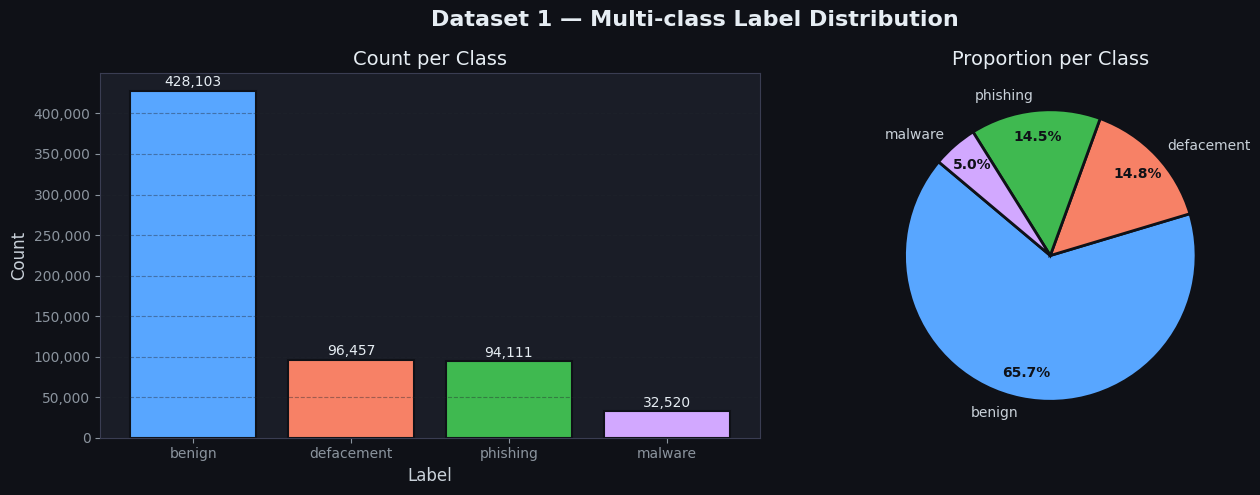


── URL Length — Dataset 1 ──
               count  mean   std   min   25%   50%    75%     max
type                                                             
benign      428103.0  57.7  44.3   6.0  31.0  46.0   71.0  2175.0
defacement   96457.0  86.3  41.9  17.0  55.0  81.0  105.0   327.0
malware      32520.0  56.5  28.4   7.0  33.0  49.0   76.0   378.0
phishing     94111.0  45.9  43.8   1.0  25.0  35.0   49.0  1779.0


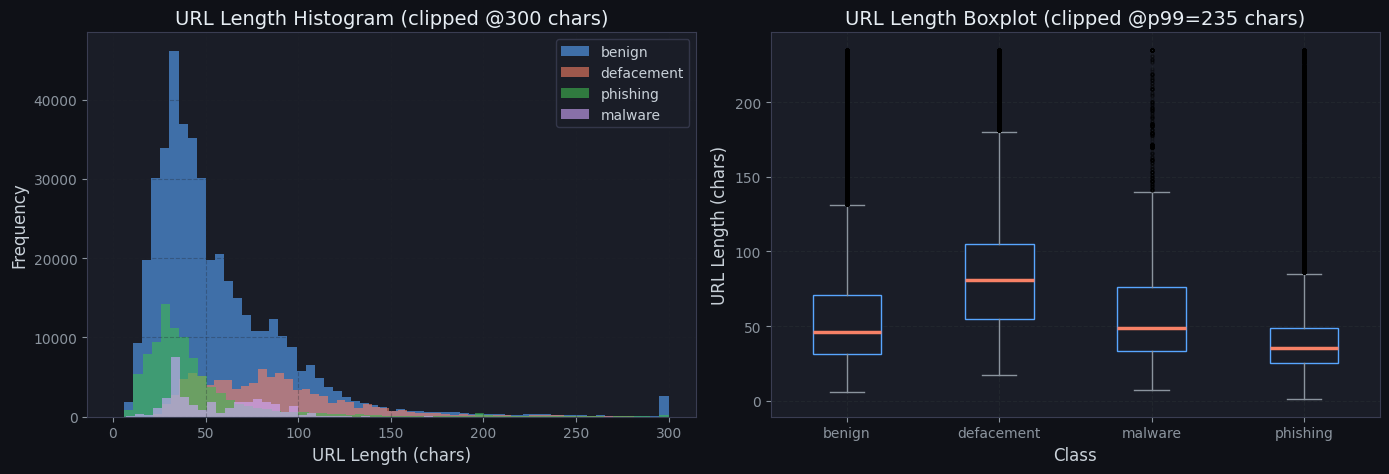

In [4]:
print("\n── EDA Dataset 1 ──")
print(df1['type'].value_counts())
print(f"Total: {len(df1)}")

label_counts1 = df1['type'].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#0f1117')
fig.suptitle('Dataset 1 — Multi-class Label Distribution', fontsize=16, color='#e6edf3', fontweight='bold')

ax = axes[0]
bars = ax.bar(label_counts1.index, label_counts1.values, color=PALETTE_4, edgecolor='#0f1117', linewidth=1.5)
ax.set_title('Count per Class', color='#e6edf3')
ax.set_xlabel('Label'); ax.set_ylabel('Count')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.grid(axis='y', alpha=0.4)
for bar, val in zip(bars, label_counts1.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2000,
            f'{val:,}', ha='center', va='bottom', fontsize=10, color='#e6edf3')

wedges, texts, autotexts = axes[1].pie(
    label_counts1.values, labels=label_counts1.index, colors=PALETTE_4,
    autopct='%1.1f%%', startangle=140, pctdistance=0.82,
    wedgeprops=dict(edgecolor='#0f1117', linewidth=2))
for t in texts: t.set_color('#c9d1d9')
for at in autotexts: at.set_color('#0f1117'); at.set_fontweight('bold')
axes[1].set_title('Proportion per Class', color='#e6edf3')

plt.tight_layout()
plt.savefig('../Reports/Images/eda_ds1_multiclass.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()
plt.close()

# URL length DS1
df1['url_len'] = df1['url'].astype(str).apply(len)

print("\n── URL Length — Dataset 1 ──")
print(df1.groupby('type')['url_len'].describe().round(1))

# Clip @p99 để boxplot không bị méo bởi outlier của benign (max=2175) và phishing (max=1779)
p99_ds1 = df1['url_len'].quantile(0.99)
df1['url_len_clip'] = df1['url_len'].clip(upper=p99_ds1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#0f1117')
fig.suptitle('Dataset 1 — URL Length by Class', fontsize=16, color='#e6edf3', fontweight='bold')

for label, color in zip(label_counts1.index, PALETTE_4):
    axes[0].hist(df1[df1['type'] == label]['url_len'].clip(upper=300),
                 bins=60, alpha=0.6, label=label, color=color)
axes[0].set_title('URL Length Histogram (clipped @300 chars)', color='#e6edf3')
axes[0].set_xlabel('URL Length (chars)'); axes[0].set_ylabel('Frequency')
axes[0].legend(facecolor='#1a1d27', edgecolor='#3a3d52', labelcolor='#c9d1d9')
axes[0].grid(alpha=0.3)

df1.boxplot(column='url_len_clip', by='type', ax=axes[1], patch_artist=True,
            boxprops=dict(facecolor='#1a1d27', color='#58a6ff'),
            medianprops=dict(color='#f78166', linewidth=2.5),
            whiskerprops=dict(color='#8b949e'), capprops=dict(color='#8b949e'),
            flierprops=dict(marker='o', color='#d2a8ff', alpha=0.25, markersize=2))
axes[1].set_facecolor('#1a1d27')
axes[1].set_title(f'URL Length Boxplot (clipped @p99={p99_ds1:.0f} chars)', color='#e6edf3')
axes[1].set_xlabel('Class'); axes[1].set_ylabel('URL Length (chars)')
plt.suptitle('')
plt.tight_layout()
plt.savefig('../Reports/Images/eda_ds1_url_length.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()
plt.close()

## 4. EDA Dataset 2 (binary)


── EDA Dataset 2 ──
Label
0    94919
1    54807
Name: count, dtype: int64
Total: 149726


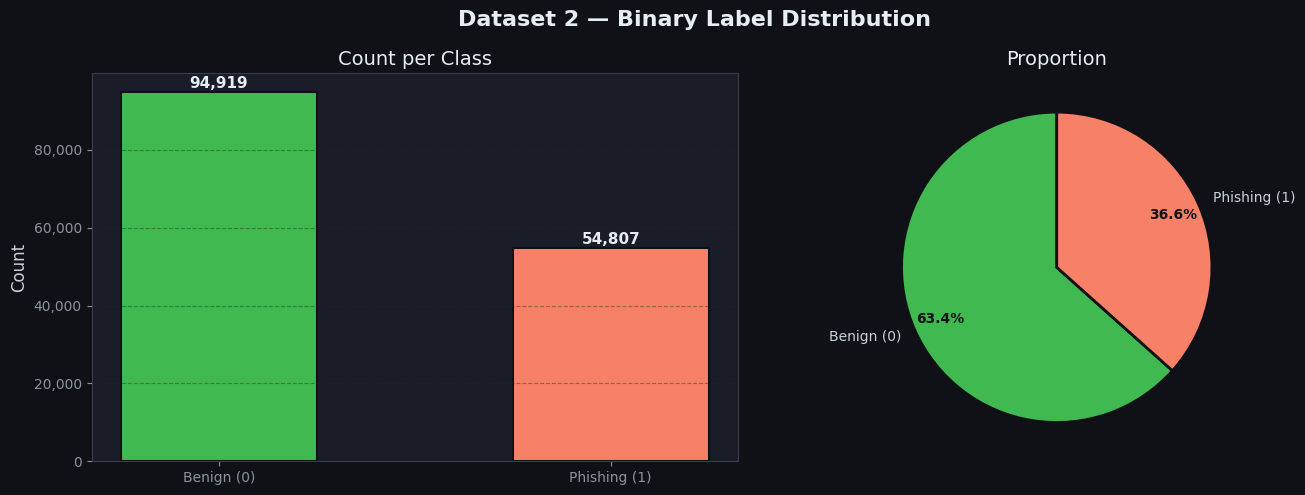


── URL Length — Dataset 2 ──
               count  mean    std   min   25%   50%   75%      max
Label                                                             
Benign(0)    94919.0  75.2   97.9  11.0  34.0  51.0  81.0   2031.0
Phishing(1)  54807.0  66.6  169.9  14.0  33.0  45.0  84.0  25523.0


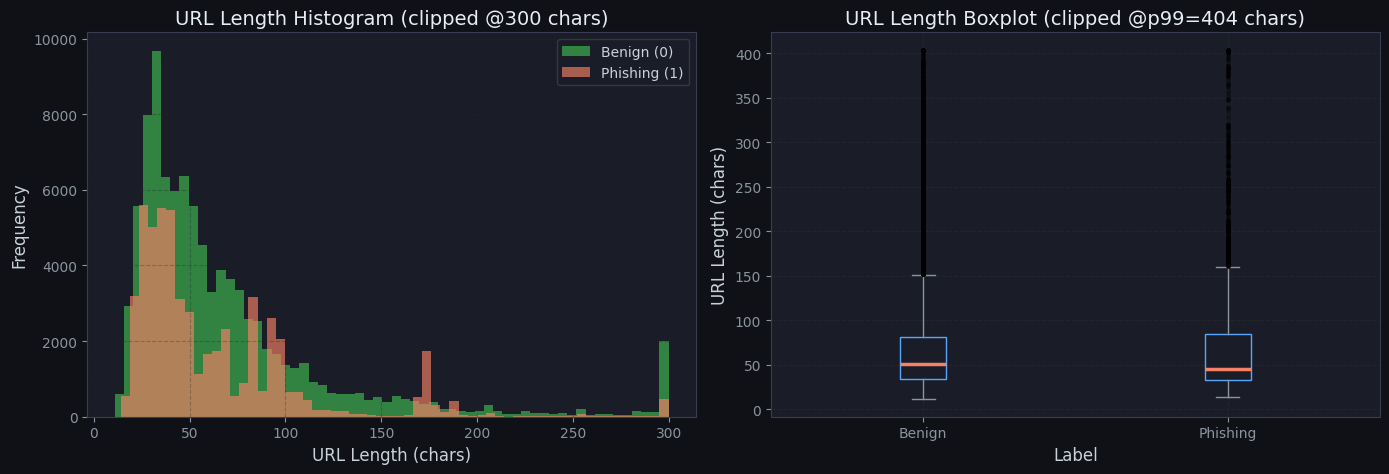

In [5]:
print("\n── EDA Dataset 2 ──")
label_counts2 = df2['Label'].value_counts().sort_index()
print(label_counts2)
print(f"Total: {len(df2)}")

df2['url_len'] = df2['URL'].astype(str).apply(len)
labels_text = ['Benign (0)', 'Phishing (1)']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#0f1117')
fig.suptitle('Dataset 2 — Binary Label Distribution', fontsize=16, color='#e6edf3', fontweight='bold')

bars = axes[0].bar(labels_text, label_counts2.values, color=PALETTE_2,
                   edgecolor='#0f1117', linewidth=1.5, width=0.5)
axes[0].set_title('Count per Class', color='#e6edf3')
axes[0].set_ylabel('Count')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
axes[0].grid(axis='y', alpha=0.4)
for bar, val in zip(bars, label_counts2.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 300,
                 f'{val:,}', ha='center', va='bottom', fontsize=11, color='#e6edf3', fontweight='bold')

wedges, texts, autotexts = axes[1].pie(
    label_counts2.values, labels=labels_text, colors=PALETTE_2,
    autopct='%1.1f%%', startangle=90, pctdistance=0.82,
    wedgeprops=dict(edgecolor='#0f1117', linewidth=2))
for t in texts: t.set_color('#c9d1d9')
for at in autotexts: at.set_color('#0f1117'); at.set_fontweight('bold')
axes[1].set_title('Proportion', color='#e6edf3')
plt.tight_layout()
plt.savefig('../Reports/Images/eda_ds2_binary.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()
plt.close()

# URL length DS2
print("\n── URL Length — Dataset 2 ──")
print(df2.groupby('Label')['url_len'].describe().round(1).rename(index={0:'Benign(0)', 1:'Phishing(1)'}))

# Clip ở p99 để boxplot không bị méo
p99 = df2['url_len'].quantile(0.99)
df2['url_len_clip'] = df2['url_len'].clip(upper=p99)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#0f1117')
fig.suptitle('Dataset 2 — URL Length Distribution by Label', fontsize=16, color='#e6edf3', fontweight='bold')

for lv, color, ls in zip([0, 1], PALETTE_2, labels_text):
    axes[0].hist(df2[df2['Label'] == lv]['url_len'].clip(upper=300),
                 bins=60, alpha=0.65, label=ls, color=color)
axes[0].set_title('URL Length Histogram (clipped @300 chars)', color='#e6edf3')
axes[0].set_xlabel('URL Length (chars)')
axes[0].set_ylabel('Frequency')
axes[0].legend(facecolor='#1a1d27', edgecolor='#3a3d52', labelcolor='#c9d1d9')
axes[0].grid(alpha=0.3)

df2['Label_str'] = df2['Label'].map({0: 'Benign', 1: 'Phishing'})
df2.boxplot(column='url_len_clip', by='Label_str', ax=axes[1], patch_artist=True,
            boxprops=dict(facecolor='#1a1d27', color='#58a6ff'),
            medianprops=dict(color='#f78166', linewidth=2.5),
            whiskerprops=dict(color='#8b949e'), capprops=dict(color='#8b949e'),
            flierprops=dict(marker='o', color='#d2a8ff', alpha=0.25, markersize=2))
axes[1].set_facecolor('#1a1d27')
axes[1].set_title(f'URL Length Boxplot (clipped @p99={p99:.0f} chars)', color='#e6edf3')
axes[1].set_xlabel('Label')
axes[1].set_ylabel('URL Length (chars)')
plt.suptitle('')
plt.tight_layout()
plt.savefig('../Reports/Images/eda_ds2_url_length.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()
plt.close()


## 5. Merge (4-Class)

In [6]:
print("\n── Merging (4 classes: benign, defacement, malware, phishing) ──")
# Dataset 1: giữ nguyên 4 nhãn gốc
ds1_clean = df1[['url', 'type']].rename(columns={'url': 'URL', 'type': 'Label'}).copy()
ds1_clean['source'] = 'dataset1'

# Dataset 2: lọc bỏ các dòng benign (Label=0) lỗi chứa '@' trong phần host (email giả dạng URL),
# sau đó ánh xạ 0 -> 'benign', 1 -> 'phishing'
ds2_raw = df2[['URL', 'Label']].copy()
bad_benign_at = (ds2_raw['Label'] == 0) & ds2_raw['URL'].astype(str).str.contains('@', regex=False)
print(f"  Filtered out {bad_benign_at.sum():,} invalid benign rows containing '@' in Dataset 2")
ds2_clean = ds2_raw[~bad_benign_at].copy()
ds2_clean['Label'] = ds2_clean['Label'].map({0: 'benign', 1: 'phishing'})
ds2_clean['source'] = 'dataset2'

df_merged = pd.concat([ds1_clean, ds2_clean], ignore_index=True)
print(f"After concat: {df_merged.shape[0]:,} rows")

priority_map = {'benign': 0, 'phishing': 1, 'defacement': 1, 'malware': 1}
n_before = len(df_merged)
df_merged['_priority'] = df_merged['Label'].map(priority_map)
df_merged_dedup = (
    df_merged
    .sort_values('_priority', ascending=False)      # ưu tiên giữ nhãn độc hại khi conflict
    .drop_duplicates(subset=['URL'], keep='first')
    .drop(columns=['_priority'])
    .sort_index()
    .reset_index(drop=True)
)
n_after = len(df_merged_dedup)
print(f"Duplicates removed: {n_before - n_after:,}  |  Final: {n_after:,} rows")


── Merging (4 classes: benign, defacement, malware, phishing) ──
  Filtered out 862 invalid benign rows containing '@' in Dataset 2
After concat: 800,055 rows
Duplicates removed: 30,078  |  Final: 769,977 rows


## 6. Normalized URL Scheme

In [7]:
print("\n── Normalize URL Scheme ──")

import re

# Chuẩn hoá URL về 1 dạng duy nhất để scheme / 'www.' KHÔNG còn mang thông tin nhãn.
# Lý do: dataset1 có 91.7% benign không có scheme (trước đây bị gắn 'http://'),
# trong khi URL 'https://' chủ yếu là malicious -> model học shortcut 'https = độc hại'.
# 'www.' cũng lệch ngược chiều giữa 2 dataset (ds1: gắn malicious, ds2: gắn benign).
# -> Bỏ scheme + 'www.', hạ chữ thường phần host, rồi gắn lại 1 scheme CỐ ĐỊNH 'http://'
#    (giữ scheme cố định để urlparse vẫn tách được domain).
# PHẢI giống hệt hàm normalize_url trong Api/features.py.
_SCHEME_RE = re.compile(r'^(?:https?|ftp)://', re.IGNORECASE)
_WWW_RE    = re.compile(r'^www\d*\.', re.IGNORECASE)

def normalize_url(url):
    u = str(url).strip()
    u = _SCHEME_RE.sub('', u)          # bỏ http:// | https:// | ftp://
    u = _WWW_RE.sub('', u)             # bỏ www. | www2. ...
    m = re.match(r'^([^/?#]*)(.*)$', u, flags=re.DOTALL)
    host, rest = m.group(1).lower(), m.group(2)
    # Chuẩn hoá dấu '/' ở gốc domain: 'domain.com' và 'domain.com/' cùng thành 'http://domain.com/'
    # (tránh model học shortcut num_slashes == 2 -> độc hại do khác biệt nguồn crawl)
    if not rest or rest[0] in ('?', '#'):
        rest = '/' + rest
    return 'http://' + host + rest

df_merged_dedup = df_merged_dedup.copy()
no_scheme_before = (~df_merged_dedup['URL'].str.lower().str.startswith(
    ('http://', 'https://', 'ftp://'))).sum()
print(f"  URLs without scheme (before): {no_scheme_before:,} ({no_scheme_before/len(df_merged_dedup)*100:.1f}%)")

df_merged_dedup['URL'] = df_merged_dedup['URL'].apply(normalize_url)

no_scheme_after = (~df_merged_dedup['URL'].str.lower().str.startswith(
    ('http://', 'https://', 'ftp://'))).sum()
print(f"  URLs without scheme (after) : {no_scheme_after:,}")
print(f"  Added 'http://' to          : {no_scheme_before - no_scheme_after:,} URLs")

# Re-dedup sau normalize — ưu tiên giữ nhãn độc hại khi conflict
n_before_renorm = len(df_merged_dedup)
priority_map = {'benign': 0, 'phishing': 1, 'defacement': 1, 'malware': 1}
df_merged_dedup['_priority'] = df_merged_dedup['Label'].map(priority_map)
df_merged_dedup = (
    df_merged_dedup
    .sort_values('_priority', ascending=False)
    .drop_duplicates(subset=['URL'], keep='first')
    .drop(columns=['_priority'])
    .sort_index()
    .reset_index(drop=True)
)
n_removed_renorm = n_before_renorm - len(df_merged_dedup)
print(f"  Re-dedup after normalization: removed {n_removed_renorm:,} | Final: {len(df_merged_dedup):,} rows")
print(f"  (Conflicting URLs retain malicious label — security-first principle)")


── Normalize URL Scheme ──
  URLs without scheme (before): 463,163 (60.2%)
  URLs without scheme (after) : 0
  Added 'http://' to          : 463,163 URLs
  Re-dedup after normalization: removed 13,134 | Final: 756,843 rows
  (Conflicting URLs retain malicious label — security-first principle)


## 7. EDA Merged


── EDA Merged Dataset (4-Class) ──
Label
benign        492692
defacement     95308
phishing      145250
malware        23593
Name: count, dtype: int64
Label
benign        65.10
defacement    12.59
phishing      19.19
malware        3.12
Name: count, dtype: float64
Total: 756843


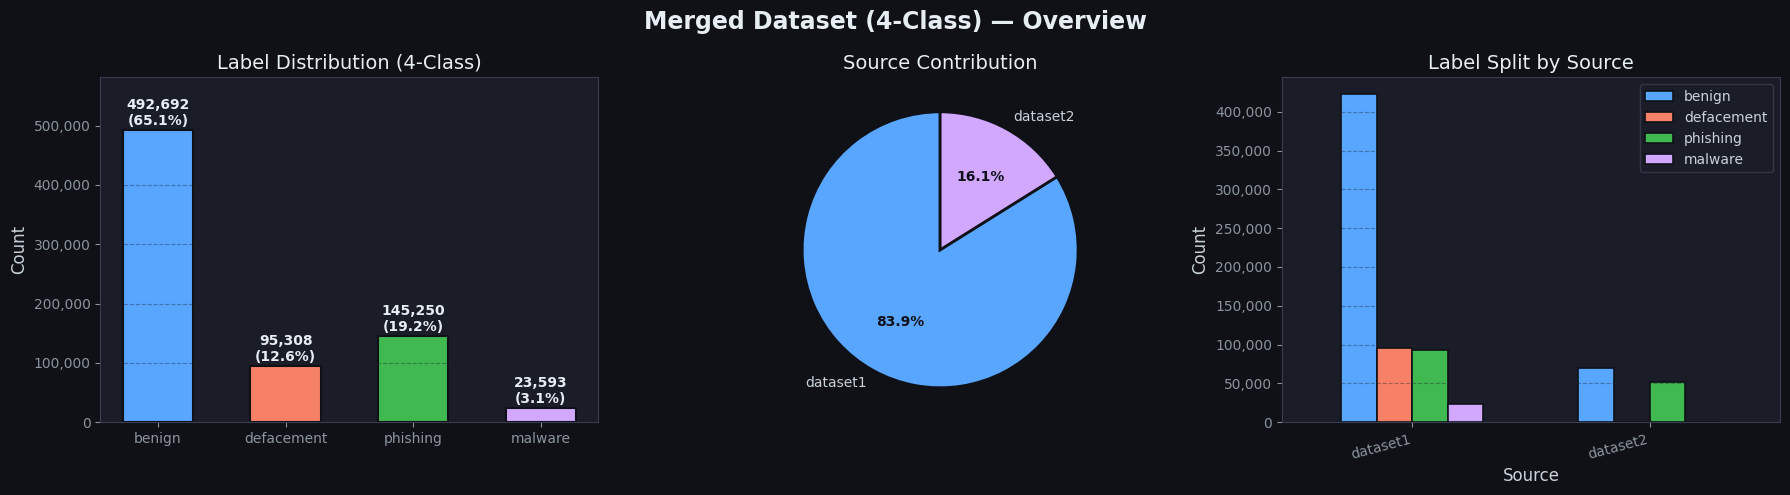


── URL Length — Merged Dataset ──
               count  mean    std   min   25%   50%    75%      max
Label                                                              
benign      492692.0  67.1   58.0  12.0  38.0  53.0   80.0   2182.0
defacement   95308.0  83.3   41.8  17.0  52.0  78.0  102.0    327.0
malware      23593.0  46.6   24.4  15.0  32.0  37.0   53.0    378.0
phishing    145250.0  55.4  109.2   9.0  31.0  40.0   60.0  25522.0


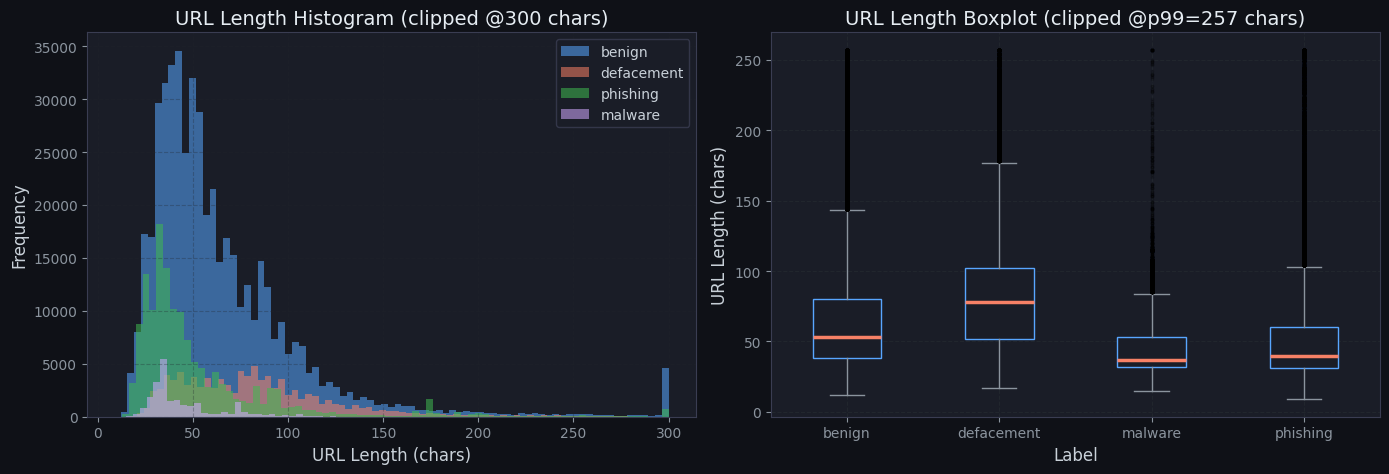

In [8]:
print("\n── EDA Merged Dataset (4-Class) ──")
LABEL_ORDER_4 = ['benign', 'defacement', 'phishing', 'malware']
merged_label_dist = df_merged_dedup['Label'].value_counts().reindex(LABEL_ORDER_4)
print(merged_label_dist)
print((merged_label_dist / len(df_merged_dedup) * 100).round(2))
print(f"Total: {len(df_merged_dedup)}")

df_merged_dedup = df_merged_dedup.copy()
df_merged_dedup['url_len'] = df_merged_dedup['URL'].astype(str).apply(len)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.patch.set_facecolor('#0f1117')
fig.suptitle('Merged Dataset (4-Class) — Overview', fontsize=17, color='#e6edf3', fontweight='bold')

# Label dist
ax = axes[0]; ax.set_facecolor('#1a1d27')
bars = ax.bar(merged_label_dist.index, merged_label_dist.values,
              color=PALETTE_4, edgecolor='#0f1117', linewidth=1.5, width=0.55)
ax.set_title('Label Distribution (4-Class)', color='#e6edf3')
ax.set_ylabel('Count')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.grid(axis='y', alpha=0.4)
ax.set_ylim(0, max(merged_label_dist.values) * 1.18)
for bar, val in zip(bars, merged_label_dist.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3000,
            f'{val:,}\n({val/len(df_merged_dedup)*100:.1f}%)',
            ha='center', va='bottom', fontsize=10, color='#e6edf3', fontweight='bold')

# Source pie
ax2 = axes[1]; ax2.set_facecolor('#1a1d27')
src = df_merged_dedup['source'].value_counts()
w, t, at = ax2.pie(src.values, labels=src.index, colors=['#58a6ff', '#d2a8ff'],
                   autopct='%1.1f%%', startangle=90,
                   wedgeprops=dict(edgecolor='#0f1117', linewidth=2))
for tt in t: tt.set_color('#c9d1d9')
for a in at: a.set_color('#0f1117'); a.set_fontweight('bold')
ax2.set_title('Source Contribution', color='#e6edf3')

# Label by source
ax3 = axes[2]; ax3.set_facecolor('#1a1d27')
cross = df_merged_dedup.groupby(['source', 'Label']).size().unstack(fill_value=0)[LABEL_ORDER_4]
cross.plot(kind='bar', ax=ax3, color=PALETTE_4, edgecolor='#0f1117', linewidth=1.2, width=0.6)
ax3.set_title('Label Split by Source', color='#e6edf3')
ax3.set_xlabel('Source'); ax3.set_ylabel('Count')
ax3.set_xticklabels(ax3.get_xticklabels(), rotation=15, ha='right')
ax3.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax3.grid(axis='y', alpha=0.4)
ax3.legend(LABEL_ORDER_4, facecolor='#1a1d27', edgecolor='#3a3d52', labelcolor='#c9d1d9')

plt.tight_layout()
plt.savefig('../Reports/Images/eda_merged_overview.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()
plt.close()

# URL length merged
print("\n── URL Length — Merged Dataset ──")
print(df_merged_dedup.groupby('Label')['url_len'].describe().round(1))

p99_merged = df_merged_dedup['url_len'].quantile(0.99)
df_merged_dedup['url_len_clip'] = df_merged_dedup['url_len'].clip(upper=p99_merged)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#0f1117')
fig.suptitle('Merged Dataset — URL Length Analysis', fontsize=16, color='#e6edf3', fontweight='bold')
for lv, color in zip(LABEL_ORDER_4, PALETTE_4):
    axes[0].hist(df_merged_dedup[df_merged_dedup['Label'] == lv]['url_len'].clip(upper=300),
                 bins=80, alpha=0.55, label=lv, color=color)
axes[0].set_title('URL Length Histogram (clipped @300 chars)', color='#e6edf3')
axes[0].set_xlabel('URL Length (chars)'); axes[0].set_ylabel('Frequency')
axes[0].legend(facecolor='#1a1d27', edgecolor='#3a3d52', labelcolor='#c9d1d9')
axes[0].grid(alpha=0.3)

df_merged_dedup.boxplot(column='url_len_clip', by='Label', ax=axes[1], patch_artist=True,
                        boxprops=dict(facecolor='#1a1d27', color='#58a6ff'),
                        medianprops=dict(color='#f78166', linewidth=2.5),
                        whiskerprops=dict(color='#8b949e'), capprops=dict(color='#8b949e'),
                        flierprops=dict(marker='o', color='#d2a8ff', alpha=0.2, markersize=1.5))
axes[1].set_facecolor('#1a1d27')
axes[1].set_title(f'URL Length Boxplot (clipped @p99={p99_merged:.0f} chars)', color='#e6edf3')
axes[1].set_xlabel('Label'); axes[1].set_ylabel('URL Length (chars)')
plt.suptitle('')
plt.tight_layout()
plt.savefig('../Reports/Images/eda_merged_url_length.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()
plt.close()

## 8. Export

In [9]:
# Chỉ xuất 2 cột ['URL', 'Label'] (4 nhãn) để dùng thống nhất cho toàn bộ pipeline phía sau
df_export = df_merged_dedup[['URL', 'Label']].reset_index(drop=True)
df_export.to_csv('../Data/Processed/merged_dataset.csv', index=False)
print(f"\nExported: merged_dataset.csv  ({df_export.shape[0]:,} rows)")
print("\nFinal Label Distribution (4-Class):")
fd = df_export['Label'].value_counts()
for k, v in fd.items():
    print(f"  {k:12s} → {v:,} ({v/len(df_export)*100:.2f}%)")


Exported: merged_dataset.csv  (756,843 rows)

Final Label Distribution (4-Class):
  benign       → 492,692 (65.10%)
  phishing     → 145,250 (19.19%)
  defacement   → 95,308 (12.59%)
  malware      → 23,593 (3.12%)
